In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import joblib
import os

print("--- Script Started ---")

--- Script Started ---


### 1. Load Data in Chunks

In [2]:
chunk_size = 50000
try:
    chunks = pd.read_csv('../data/creditcard.csv', chunksize=chunk_size)
    print("CSV chunks created.")
except Exception as e:
    print(f"Error creating chunks: {e}")

fraud_df = pd.DataFrame()
non_fraud_df = pd.DataFrame()

print('Processing data in chunks...')
i = 0
for chunk in chunks:
    i += 1
    print(f"Processing chunk {i}...")
    fraud_chunk = chunk[chunk['Class'] == 1]
    non_fraud_chunk = chunk[chunk['Class'] == 0]
    fraud_df = pd.concat([fraud_df, fraud_chunk])
    non_fraud_df = pd.concat([non_fraud_df, non_fraud_chunk])

print('Finished processing chunks.')
print(f"Found {len(fraud_df)} fraud transactions and {len(non_fraud_df)} non-fraud transactions.")

CSV chunks created.
Processing data in chunks...
Processing chunk 1...
Processing chunk 2...
Processing chunk 3...
Processing chunk 4...
Processing chunk 5...
Processing chunk 6...
Finished processing chunks.
Found 492 fraud transactions and 284315 non-fraud transactions.


### 2. Undersample and Combine

In [3]:
f_count = len(fraud_df)
non_fraud_undersampled = non_fraud_df.sample(n=f_count, random_state=42)
print("Undersampling complete.")

# Combine to create the final balanced DataFrame
df = pd.concat([fraud_df, non_fraud_undersampled])
print("Combined fraud and non-fraud samples.")

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print("Dataset shuffled.")

Undersampling complete.
Combined fraud and non-fraud samples.
Dataset shuffled.


### 3. Preprocessing

In [4]:
print("Starting preprocessing...")
scaler = StandardScaler()
df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1, 1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1, 1))
df.drop(['Time', 'Amount'], axis=1, inplace=True)
print("Preprocessing complete.")

X = df.drop('Class', axis=1)
y = df['Class']

Starting preprocessing...
Preprocessing complete.


### 4. Model Training

In [9]:
print("Splitting data...")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data split. Starting model training...")

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
print("Model training complete.")

Splitting data...
Data split. Starting model training...
Model training complete.


### 5. Save Model and Scaler

In [12]:
print("Saving model and scaler...")
model_path = '../models/fraud_detection_model.joblib'
scaler_path = '../models/scaler.joblib'

# Ensure the 'models' directory exists
os.makedirs('../models', exist_ok=True)

joblib.dump(model, model_path)
joblib.dump(scaler, scaler_path)

if os.path.exists(model_path) and os.path.exists(scaler_path):
    print('Model and scaler saved successfully.')
else:
    print('Error: Model or scaler saving failed.')

Saving model and scaler...
Model and scaler saved successfully.


### 6. Evaluation

Evaluating model...
--- Classification Report ---
              precision    recall  f1-score   support

           0       0.90      0.95      0.93        87
           1       0.96      0.92      0.94       110

    accuracy                           0.93       197
   macro avg       0.93      0.94      0.93       197
weighted avg       0.94      0.93      0.93       197

--- Confusion Matrix ---
[[ 83   4]
 [  9 101]]


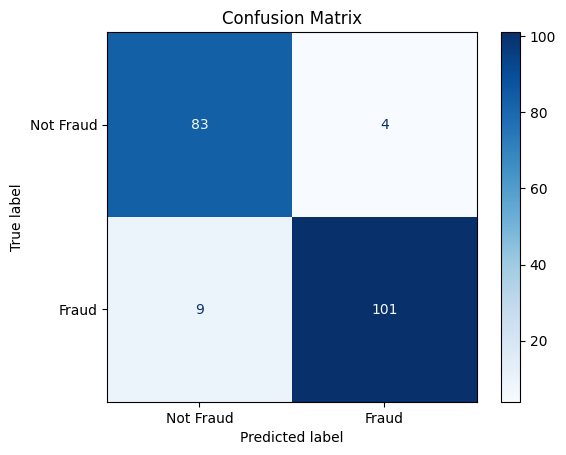

Model Accuracy: 93.40%


In [14]:
print("Evaluating model...")
y_pred = model.predict(X_test)

print('--- Classification Report ---')
print(classification_report(y_test, y_pred))

print('--- Confusion Matrix ---')
print(confusion_matrix(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])  # 0: Not Fraud, 1: Fraud
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Fraud', 'Fraud'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")
